In [1]:
import eu9_osm
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib_map_utils.core.scale_bar import scale_bar

In [2]:
# Params
bbox = (-7.47345, 37.18774, -7.44187, 37.21637)

crs = "EPSG:3763"

tags = {
    "landuse": [
        "farmland", "farmyard", "meadow",
        "forest", "orchard",
        "salt_pond"
    ],
    "water": True,
    "waterway": True
}

In [3]:
# Polygons and lines
gdf = eu9_osm.features_from_bbox(bbox=bbox, tags=tags, clip=True)

gdf["geom_type"] = gdf.geometry.geom_type
gdf = gdf[gdf["geom_type"] != "Point"]

poly_gdf = gdf[gdf.geometry.geom_type.isin(["Polygon", "MultiPolygon"])]
line_gdf = gdf[gdf.geometry.geom_type.isin(["LineString", "MultiLineString"])]

line_gdf = line_gdf.to_crs(crs)
poly_gdf = poly_gdf.to_crs(crs)

In [4]:
# Relevant columns
poly_gdf = poly_gdf[["tags_json", "geometry"]].copy()
poly_gdf["row_num"] = range(len(poly_gdf))

In [5]:
# Merge with colors
df = pd.read_csv("colors.csv")
merged_gdf = poly_gdf.merge(df, on="row_num", how="left")

In [6]:
months = [
    "january",
    "february",
    "march",
    "april",
    "may",
    "june",
    "july",
    "august",
    "september",
    "october",
    "november",
    "december"
]

# Frames per month
steps = 20

# Total frames
total_frames = 12 * steps

# Monthly rgb arrays
monthly_rgb = np.stack([merged_gdf[[f"{month}_R", f"{month}_G", f"{month}_B"]].to_numpy(dtype=float) for month in months])

In [7]:
# Nearest poly
nearest = gpd.sjoin_nearest(line_gdf, merged_gdf[["geometry", "row_num"]], how="left", distance_col="distance_m")
# Drop duplicates
nearest = nearest[~nearest.index.duplicated(keep="first")].copy()

# Convert polygon ids to positions 
polygon_positions = dict(zip(merged_gdf["row_num"], range(len(merged_gdf))))
# Map positions
nearest["polygon_position"] = nearest["row_num"].map(polygon_positions)

# Drop unmatched lines
nearest = nearest.dropna(subset=["polygon_position"]).copy()
# Integer arrays
line_positions = nearest["polygon_position"].to_numpy(dtype=int)
# Initial colours
initial_colours = np.nan_to_num(monthly_rgb[0] / 255, nan=0.5)

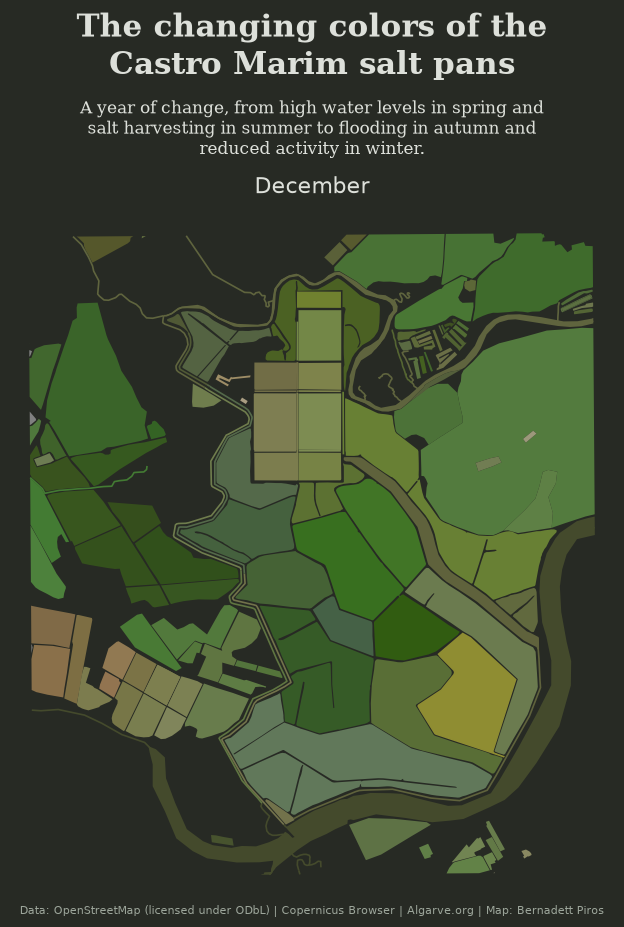

In [8]:
fig, ax = plt.subplots(figsize=(10, 10), facecolor="#272a24")

# Polygons
merged_gdf.plot(ax=ax, color=[tuple(rgb) for rgb in initial_colours], ec="none")
polygon_collection = ax.collections[-1]

# Lines
nearest.plot(ax=ax, color=[tuple(rgb) for rgb in initial_colours[line_positions]], lw=1.2)
line_collection = ax.collections[-1]

# Axis lims
xmin, ymin, xmax, ymax = merged_gdf.total_bounds
padding = 0.03 * max(xmax - xmin, ymax - ymin)
ax.set_xlim(xmin - padding, xmax + padding)
ax.set_ylim(ymin - padding, ymax + padding)

ax.set_facecolor("#272a24")
ax.set_aspect("equal")
ax.axis("off")

#plt.subplots_adjust(left=0.02, right=0.98, bottom=0.02, top=0.94)
plt.subplots_adjust(left=0.05, right=0.95, bottom=0.12, top=0.80)

# Title
fig.text(0.5, 0.94, 
         "The changing colors of the\nCastro Marim salt pans",
         size=22, color="#dde0da", weight="bold", fontfamily="serif", ha="center")    

# Subtitle
fig.text(0.5, 0.86,
         "A year of change, from high water levels in spring and\n"
          "salt harvesting in summer to flooding in autumn and\n"
          "reduced activity in winter.",
         size=12, color="#dde0da", fontfamily="serif", ha="center")   

# Caption
fig.text(0.5, 0.1,
         "Data: OpenStreetMap (licensed under ODbL) | Copernicus Browser | Algarve.org | Map: Bernadett Piros",
          size=8, color="#9da69b", ha="center")

# Update
def update(frame):

    # Current month
    month_index = (frame // steps) % 12

    # Interpolation fraction
    fraction = (frame % steps) / steps

    # Next month
    next_index = (month_index + 1) % 12

    # Interpolate rgb values
    rgb = (monthly_rgb[month_index] * (1 - fraction) + monthly_rgb[next_index] * fraction)

    # Normalize rgb
    rgb = np.clip(rgb / 255, 0, 1)

    # Missing colours
    rgb = np.nan_to_num(rgb, nan=0.5)

    # Update polygons
    polygon_collection.set_facecolors(rgb)

    # Update lines
    line_collection.set_color(rgb[line_positions])

    # Update title
    ax.set_title(
        f"{months[month_index].capitalize()}",
        fontsize=16, color="#dde0da", pad=15)

    return polygon_collection, line_collection

# Animation
ani = FuncAnimation(fig, update, frames=total_frames, interval=80, blit=False, repeat=True)

# Save
ani.save("seasonal_colors.gif", writer=PillowWriter(fps=15),  dpi=120)

plt.show()